<a href="https://colab.research.google.com/github/Nihat0311/NLP/blob/main/Sentence_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tiktoken sentence-transformers scikit-learn matplotlib numpy

In [ ]:
import tiktoken
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import random

def chunk_text_by_tokens(text, chunk_size, overlap=0):
    encoder = tiktoken.get_encoding("cl100k_base")
    tokens = encoder.encode(text)

    chunks = []
    i = 0
    while i < len(tokens):
        chunk_tokens = tokens[i : i + chunk_size]
        chunks.append(encoder.decode(chunk_tokens))
        i += (chunk_size - overlap)
    return chunks

document_text = """
Welcome to the company. We are thrilled to have you join our team. This handbook is designed to acquaint you with our policies, working conditions, and the benefits available to you. You are expected to read, understand, and comply with all provisions of this handbook.

Section 1: Working Hours. Our standard business hours are 9:00 AM to 5:00 PM, Monday through Friday. However, individual team schedules may vary based on operational needs and remote work arrangements. Remote employees must remain reachable during core hours (10:00 AM to 3:00 PM).

Section 2: Paid Time Off (PTO). Full-time employees accrue PTO at a rate of 1.5 days per month, totaling 18 days per calendar year. PTO requests must be submitted at least two weeks in advance and approved by your direct supervisor. Unused PTO up to 5 days can carry over to the next calendar year; any additional unused accrued time will be forfeited.

Section 3: Sick Leave. Employees receive 10 paid sick days annually for personal illness or family care. A doctor's note is required for consecutive absences exceeding 3 days.

Section 4: Code of Conduct. We maintain a zero-tolerance policy for harassment, discrimination, or bullying of any kind. All employees must act with integrity, respect, and professionalism.

Section 5: Data Security. Protecting client and company data is critical. Employees must use strong passwords, enable Multi-Factor Authentication (MFA), and avoid accessing sensitive files over unsecured public Wi-Fi networks. Failure to comply with security guidelines may result in disciplinary action up to termination.
"""

for size in [200, 500, 1000]:
    res_chunks = chunk_text_by_tokens(document_text, chunk_size=size)
    print(f"\n===== CHUNK SIZE: {size} TOKENS (Cəmi {len(res_chunks)} chunk) =====")
    for idx, chunk in enumerate(res_chunks[:5]):
        print(f"Chunk {idx+1}:\n{chunk.strip()}")
        print("-" * 50)


===== CHUNK SIZE: 200 TOKENS (Cəmi 2 chunk) =====
Chunk 1:
Welcome to the company. We are thrilled to have you join our team. This handbook is designed to acquaint you with our policies, working conditions, and the benefits available to you. You are expected to read, understand, and comply with all provisions of this handbook. 

Section 1: Working Hours. Our standard business hours are 9:00 AM to 5:00 PM, Monday through Friday. However, individual team schedules may vary based on operational needs and remote work arrangements. Remote employees must remain reachable during core hours (10:00 AM to 3:00 PM). 

Section 2: Paid Time Off (PTO). Full-time employees accrue PTO at a rate of 1.5 days per month, totaling 18 days per calendar year. PTO requests must be submitted at least two weeks in advance and approved by your direct supervisor. Unused PTO up to 5 days can carry over to the next calendar year; any additional unused accrued time will
---------------------------------------------

In [ ]:
model = SentenceTransformer('all-MiniLM-L6-v2')

chunks = [
    "How to enroll in university courses.",
    "Student registration process.",
    "Tuition fees must be paid before registration.",
    "Students are required to pay tuition prior to enrolling.",

    "A deep learning model architecture.",
    "Training neural networks with backpropagation.",
    "Database indexing strategies.",
    "Optimizing SQL query execution times.",

    "Weather forecast for tomorrow afternoon.",
    "Heavy rain and strong winds expected.",

    "The rules of professional soccer.",
    "World Cup final match details.",

    "Healthy diet and nutritional planning.",
    "Superfoods that boost immune system health.",

    "How to balance an investment portfolio.",
    "Stock market trading strategies.",

    "The history of Roman architecture.",
    "Ancient Greek philosophical schools.",

    "Electric vehicle battery technology.",
    "Lithium-ion cell manufacturing processes."
]

embeddings = model.encode(chunks)

similarity_matrix = cosine_similarity(embeddings)

pairs = []
for i in range(len(chunks)):
    for j in range(i+1, len(chunks)):
        pairs.append((similarity_matrix[i][j], chunks[i], chunks[j]))

pairs.sort(reverse=True)

print("=== TASK 2: ƏN OXŞAR 5 CÜTLÜK ===")
for sim, c1, c2 in pairs[:5]:
    print(f"Oxşarlıq: {sim:.4f} | '{c1}' <=> '{c2}'")

print("\n=== TASK 2: ƏN AZ OXŞAR 5 CÜTLÜK ===")
for sim, c1, c2 in pairs[-5:]:
    print(f"Oxşarlıq: {sim:.4f} | '{c1}' <=> '{c2}'")

# 2. Task 3 üçün: Threshold > 0.85 olan dublikatları tapmaq
print("\n=== TASK 3: AŞKARLANAN DUBLİKATLAR (Oxşarlıq > 0.85) ===")
duplicates = [p for p in pairs if p[0] > 0.85]
if len(duplicates) == 0:
    print("Müəyyən edilmiş limitdə dublikat tapılmadı.")
else:
    for sim, c1, c2 in duplicates:
        print(f"[AŞKARLANDI - Oxşarlıq: {sim:.4f}]\n  Mətn A: {c1}\n  Mətn B: {c2}\n")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

=== TASK 2: ƏN OXŞAR 5 CÜTLÜK ===
Oxşarlıq: 0.8282 | 'Tuition fees must be paid before registration.' <=> 'Students are required to pay tuition prior to enrolling.'
Oxşarlıq: 0.5769 | 'Student registration process.' <=> 'Students are required to pay tuition prior to enrolling.'
Oxşarlıq: 0.5647 | 'Student registration process.' <=> 'Tuition fees must be paid before registration.'
Oxşarlıq: 0.5645 | 'Database indexing strategies.' <=> 'Optimizing SQL query execution times.'
Oxşarlıq: 0.4908 | 'How to enroll in university courses.' <=> 'Students are required to pay tuition prior to enrolling.'

=== TASK 2: ƏN AZ OXŞAR 5 CÜTLÜK ===
Oxşarlıq: -0.0913 | 'Tuition fees must be paid before registration.' <=> 'World Cup final match details.'
Oxşarlıq: -0.0932 | 'World Cup final match details.' <=> 'How to balance an investment portfolio.'
Oxşarlıq: -0.0973 | 'Student registration process.' <=> 'Superfoods that boost immune system health.'
Oxşarlıq: -0.1058 | 'Tuition fees must be paid before re

In [ ]:
print("=== TASK 4: CHUNK RECONSTRUCTION CHALLENGE ===")

original_article = [
    "Introduction: Renewable energy is growing globally.", # Chunk 1
    "Historically, wind power was used for milling grains.", # Chunk 2
    "Today, modern wind turbines generate gigawatts of electricity.", # Chunk 3
    "Conclusion: Transitioning to clean energy is inevitable." # Chunk 4
]

# Chunkları qarışdırırıq
shuffled_article = original_article.copy()
random.shuffle(shuffled_article)

print("\nQarışdırılmış Chunklar:")
for idx, text in enumerate(shuffled_article):
    print(f"[{idx}]: {text}")

print("\nBərpa Prosesi Analizi:")
print("1. Overlap (Üst-üstə düşmə) olmadan: Yalnız məna əlaqələrinə əsasən bərpa etməlisiniz (Çətinlik: Yüksək).")
print("2. 100-token Overlap olduqda: Hər chunk-ın son sözləri növbəti chunk-ın əvvəlində təkrarlandığı üçün bərpa çox asanlaşır (Çətinlik: Çox Asan).")

=== TASK 4: CHUNK RECONSTRUCTION CHALLENGE ===

Qarışdırılmış Chunklar:
[0]: Today, modern wind turbines generate gigawatts of electricity.
[1]: Introduction: Renewable energy is growing globally.
[2]: Historically, wind power was used for milling grains.
[3]: Conclusion: Transitioning to clean energy is inevitable.

Bərpa Prosesi Analizi:
1. Overlap (Üst-üstə düşmə) olmadan: Yalnız məna əlaqələrinə əsasən bərpa etməlisiniz (Çətinlik: Yüksək).
2. 100-token Overlap olduqda: Hər chunk-ın son sözləri növbəti chunk-ın əvvəlində təkrarlandığı üçün bərpa çox asanlaşır (Çətinlik: Çox Asan).


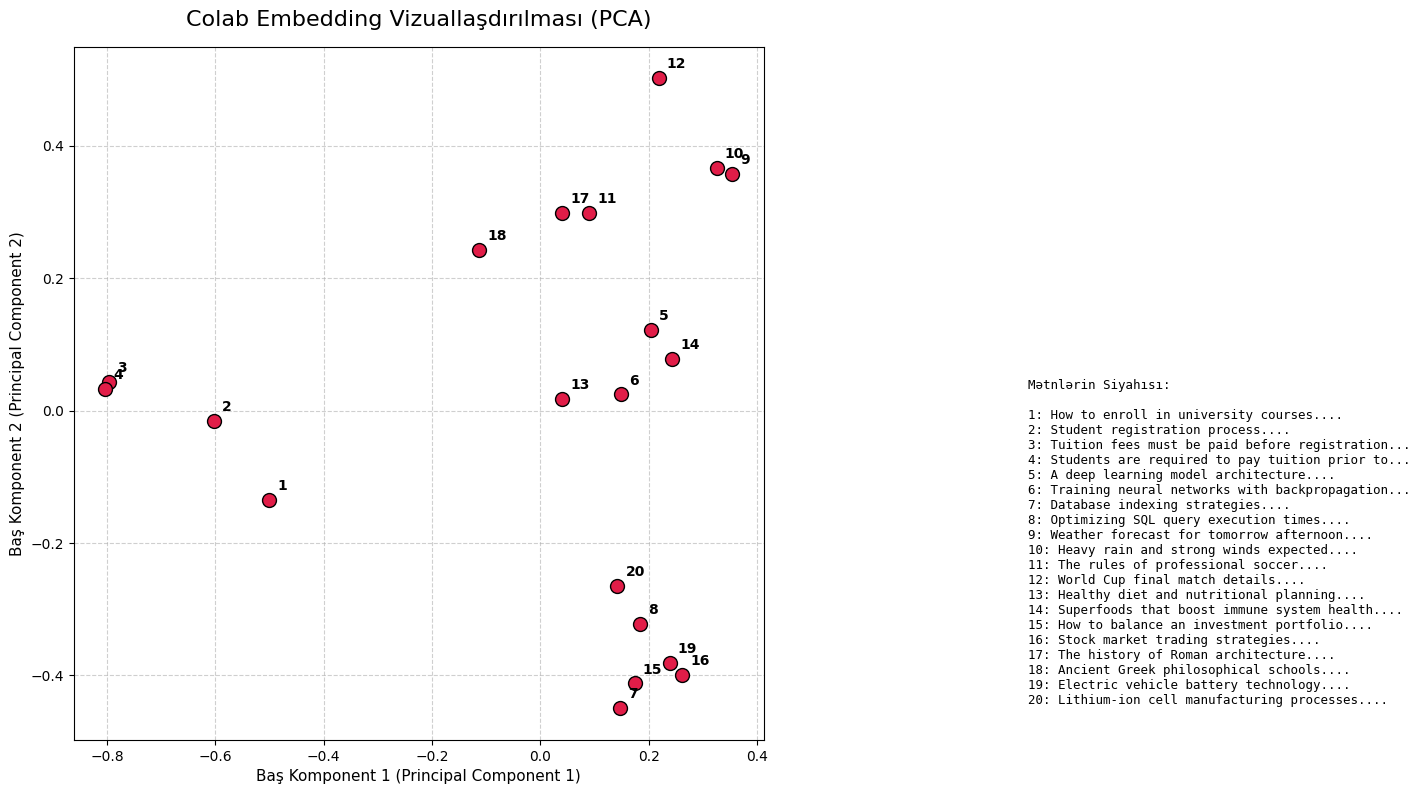

In [ ]:
# Embedding-ləri 2-ölçülü fəzaya endiririk
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(embeddings)

# Qrafik çəkilməsi
plt.figure(figsize=(12, 9))
plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], color='#e11d48', edgecolor='black', s=100, zorder=3)

# Nöqtələrin yanına müvafiq cümlələrin qısa nömrələrini əlavə etmək
for i, (x, y) in enumerate(reduced_vectors):
    plt.text(x + 0.015, y + 0.015, f"{i+1}", fontsize=10, weight='bold', zorder=4)

plt.title("Colab Embedding Vizuallaşdırılması (PCA)", fontsize=16, pad=15)
plt.xlabel("Baş Komponent 1 (Principal Component 1)", fontsize=11)
plt.ylabel("Baş Komponent 2 (Principal Component 2)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6, zorder=1)

# Sağ tərəfdə hansı nömrənin hansı cümləyə aid olduğunu göstərən siyahı
info_text = "\n".join([f"{i+1}: {chunks[i][:45]}..." for i in range(len(chunks))])
plt.gcf().text(0.92, 0.15, f"Mətnlərin Siyahısı:\n\n{info_text}", fontsize=9, family='monospace')

plt.subplots_adjust(right=0.7) # Sağdakı siyahıya yer ayırmaq üçün
plt.show()